<a href="https://colab.research.google.com/github/wadeea23/Age-Prediction/blob/main/wadeea_lab_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten , Conv2D, MaxPooling2D
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report ,recall_score


**part 1**

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [29]:
zip_path = "/content/drive/MyDrive/GA/labCNN/labCNN.zip"
extract_path = "/content/labCNN"

In [32]:
with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print(os.listdir(extract_path))

['UTKFace', 'crop_part1', 'utkface_aligned_cropped']


In [45]:
images_path = "/content/labCNN/UTKFace"
paths = glob.glob(os.path.join(images_path, "**", "*.jpg"), recursive=True)
print("Total images:", len(paths))

Total images: 23708


In [51]:
ages = []

for p in paths:
    name = os.path.basename(p)
    age = int(name.split("_")[0])
    ages.append(age)

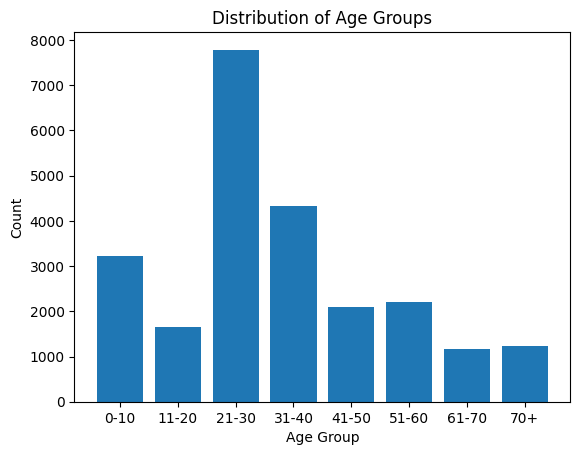

In [53]:
bins = [0, 10, 20, 30, 40, 50, 60, 70, 120]
labels = ["0-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61-70", "70+"]

age_groups = pd.cut(ages, bins=bins, labels=labels)
counts = age_groups.value_counts().sort_index()

plt.bar(counts.index, counts.values)
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.title("Distribution of Age Groups")
plt.show()


- The data is imbalanced: the 21-30 age group has the most images, while the other age groups especially 61-70 and 70+ have far fewer images.


In [54]:
X = []
y = []

for p in paths:
    age = int(os.path.basename(p).split("_")[0])

    img = Image.open(p)
    img = img.resize((48, 48))

    X.append(np.array(img))
    y.append(age)

X = np.array(X)
y = np.array(y)

print(X.shape, y.shape)

(23708, 48, 48, 3) (23708,)


In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [59]:
#normalized to 0,1
X_train=X_train/255
X_val=X_val/255
X_test=X_test/255
print(X_train.min(), X_train.max())

0.0 1.0


**PART 2**
Neural Network

In [64]:
model = Sequential()
model.add(Input(shape=(48, 48,3)))

model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(1))


In [65]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,649 (1.36 MB)

 Trainable params: 355,649 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [72]:
model.compile(optimizer='adam', loss='mae', metrics=['acc'])

In [73]:
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 64s 132ms/step - acc: 0.0484 - loss: 15.5797 - val_acc: 0.0451 - val_loss: 14.1105
Epoch 2/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 59s 123ms/step - acc: 0.0457 - loss: 12.1290 - val_acc: 0.0427 - val_loss: 10.9747
Epoch 3/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 59s 125ms/step - acc: 0.0448 - loss: 11.0120 - val_acc: 0.0414 - val_loss: 10.2013
Epoch 4/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 63s 132ms/step - acc: 0.0457 - loss: 10.1060 - val_acc: 0.0448 - val_loss: 9.4112
Epoch 5/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 80s 128ms/step - acc: 0.0448 - loss: 9.2015 - val_acc: 0.0419 - val_loss: 8.8216
Epoch 6/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 63s 133ms/step - acc: 0.0454 - loss: 8.6989 - val_acc: 0.0427 - val_loss: 8.4681
Epoch 7/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 60s 126ms/step - acc: 0.0461 - loss: 8.2286 - val_acc: 0.0445 - val_loss: 9.1343
Epoch 8/10
475/475 ━━━━━━━━━━━━━━━━━━━━ 59s 124ms/step - acc: 0.0465 - loss: 7.7152 - val_acc: 0.0445 - val_loss: 7.7560
Epoch 9/10
475/475 ━━━━━━

<Axes: >

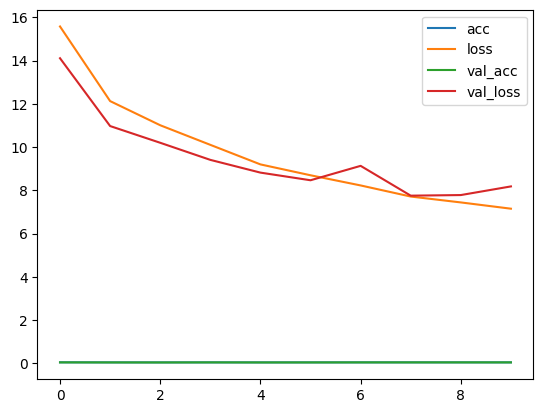

In [74]:
pd.DataFrame(history.history).plot()

In [75]:
teat_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", teat_loss)

149/149 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - acc: 0.0456 - loss: 8.1528
Test Accuracy: 0.045550402253866196
Test Loss: 8.152764320373535


In [76]:
confusion_matrix(y_test, np.argmax(model.predict(X_test), axis=1))

149/149 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step


array([[  0,   0,   0, ...,   0,   0,   0],
       [216,   0,   0, ...,   0,   0,   0],
       [103,   0,   0, ...,   0,   0,   0],
       ...,
       [  4,   0,   0, ...,   0,   0,   0],
       [  1,   0,   0, ...,   0,   0,   0],
       [  1,   0,   0, ...,   0,   0,   0]])

In [77]:
classification_report(y_test, np.argmax(model.predict(X_test), axis=1))

149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

'              precision    recall  f1-score   support\n\n           0       0.00      0.00      0.00       0.0\n           1       0.00      0.00      0.00     216.0\n           2       0.00      0.00      0.00     103.0\n           3       0.00      0.00      0.00      75.0\n           4       0.00      0.00      0.00      62.0\n           5       0.00      0.00      0.00      40.0\n           6       0.00      0.00      0.00      21.0\n           7       0.00      0.00      0.00      29.0\n           8       0.00      0.00      0.00      53.0\n           9       0.00      0.00      0.00      30.0\n          10       0.00      0.00      0.00      32.0\n          11       0.00      0.00      0.00      18.0\n          12       0.00      0.00      0.00      25.0\n          13       0.00      0.00      0.00      18.0\n          14       0.00      0.00      0.00      37.0\n          15       0.00      0.00      0.00      31.0\n          16       0.00      0.00      0.00      47.0\n       

In [78]:
recall_score(y_test, np.argmax(model.predict(X_test), axis=1), average=None)

149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

**part 3 **

149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step


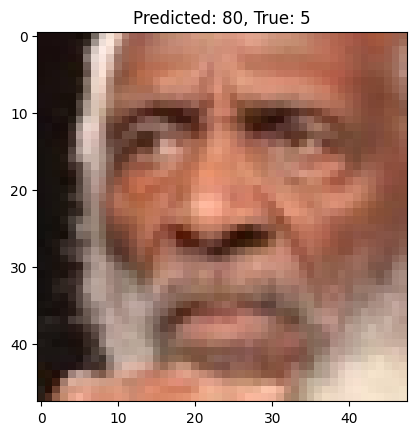

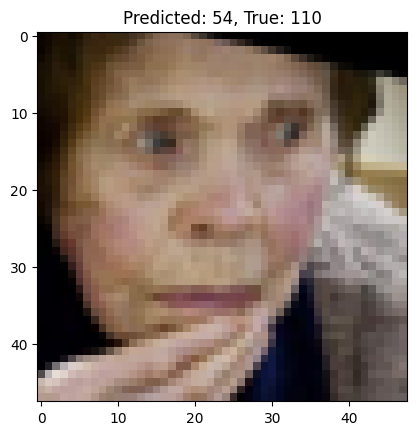

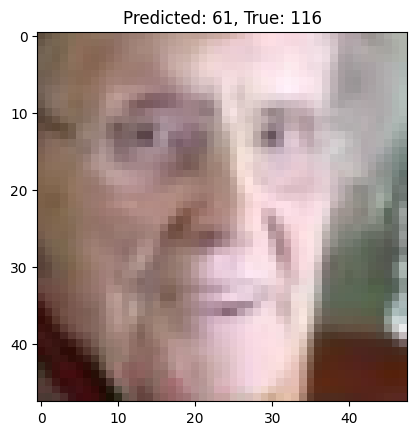

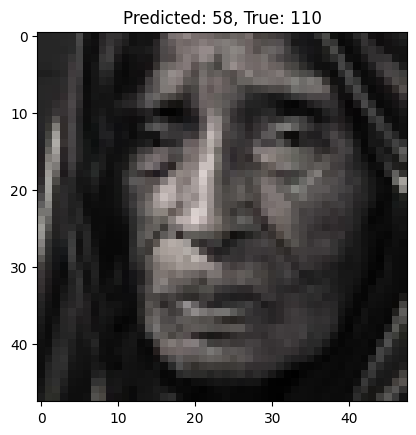

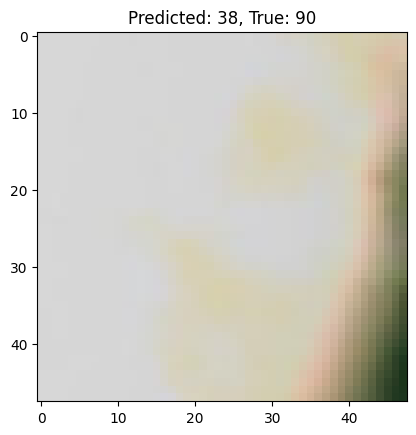

In [79]:
y_pred = model.predict(X_test).flatten()

error = abs(y_pred - np.array(y_test))
worst = np.argsort(error)[::-1]

for i in worst[:5]:
    plt.imshow(X_test[i])
    plt.title("Predicted: " + str(round(y_pred[i])) +
              ", True: " + str(y_test[i]))
    plt.show()

The model made mistakes because age is difficult to predict from faces, and image quality and unbalanced age groups can affect accuracy.

In [80]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [81]:
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val), callbacks=[early_stopping])

Epoch 1/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 75s 127ms/step - acc: 0.0450 - loss: 7.0354 - val_acc: 0.0456 - val_loss: 15.5591
Epoch 2/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 78s 132ms/step - acc: 0.0447 - loss: 6.8637 - val_acc: 0.0456 - val_loss: 15.4445
Epoch 3/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 87s 140ms/step - acc: 0.0438 - loss: 6.6629 - val_acc: 0.0456 - val_loss: 15.6870
Epoch 4/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 131s 123ms/step - acc: 0.0443 - loss: 6.5055 - val_acc: 0.0456 - val_loss: 15.2487
Epoch 5/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 74s 125ms/step - acc: 0.0440 - loss: 6.3087 - val_acc: 0.0456 - val_loss: 15.8352
Epoch 6/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 77s 130ms/step - acc: 0.0431 - loss: 6.1593 - val_acc: 0.0456 - val_loss: 16.7660
Epoch 7/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 78s 123ms/step - acc: 0.0419 - loss: 5.9723 - val_acc: 0.0456 - val_loss: 15.5055
Epoch 8/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 73s 124ms/step - acc: 0.0424 - loss: 5.7508 - val_acc: 0.0456 - val_loss: 16.2334
Epoch 9/10
593/593 ━━━━

In [82]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - acc: 0.0426 - loss: 7.1808
Test Accuracy: 0.04259806126356125
Test Loss: 7.180810451507568


**part 4**

In [83]:
!pip install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 24.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 58.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit]


In [93]:
%%writefile /content/age_app.py

import streamlit as st
import numpy as np
from PIL import Image
from tensorflow.keras.models import load_model

model = load_model("/content/age_model.keras")

st.title("Age Estimator")

uploaded_image = st.file_uploader("Upload Image", type=["jpg", "jpeg", "png"])

open_camera = st.checkbox("Open Camera")

camera_image = None

if open_camera:
    camera_image = st.camera_input("Take a Photo")

if uploaded_image is not None:
    image_file = uploaded_image
elif camera_image is not None:
    image_file = camera_image
else:
    image_file = None

if image_file is not None:
    image = Image.open(image_file)
    st.image(image)

    if st.button("Predict Age"):
        image = image.convert("RGB").resize((48, 48))
        image = np.array(image) / 255.0
        image = np.expand_dims(image, axis=0)

        prediction = model.predict(image, verbose=0)
        age = round(prediction[0][0])

        st.success(f"Estimated Age: {age} years old")


Overwriting /content/age_app.py


In [ ]:
!streamlit run /content/age_app.py --server.port 8501 &>/content/logs.txt &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦your url is: https://bright-towns-matter.loca.lt


In [92]:
model.save("/content/age_model.keras")